In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import California Housing dataset
from sklearn.datasets import fetch_california_housing

# Load the dataset
housing = fetch_california_housing(as_frame=True)

# Create a DataFrame
df = housing.frame

# Display the first five rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (20640, 9)

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [3]:
# Display statistical summary of the dataset
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
5    2.697
6    2.992
7    2.414
8    2.267
9    2.611
Name: MedHouseVal, dtype: float64


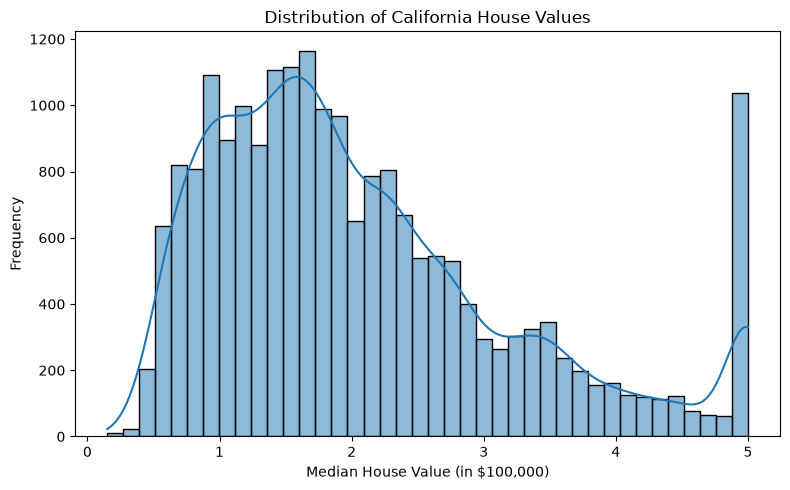

In [4]:
# Display the first 10 house values
print(df["MedHouseVal"].head(10))

# Plot the distribution of house values
plt.figure(figsize=(8, 5))
sns.histplot(df["MedHouseVal"], bins=40, kde=True)

plt.title("Distribution of California House Values")
plt.xlabel("Median House Value (in $100,000)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

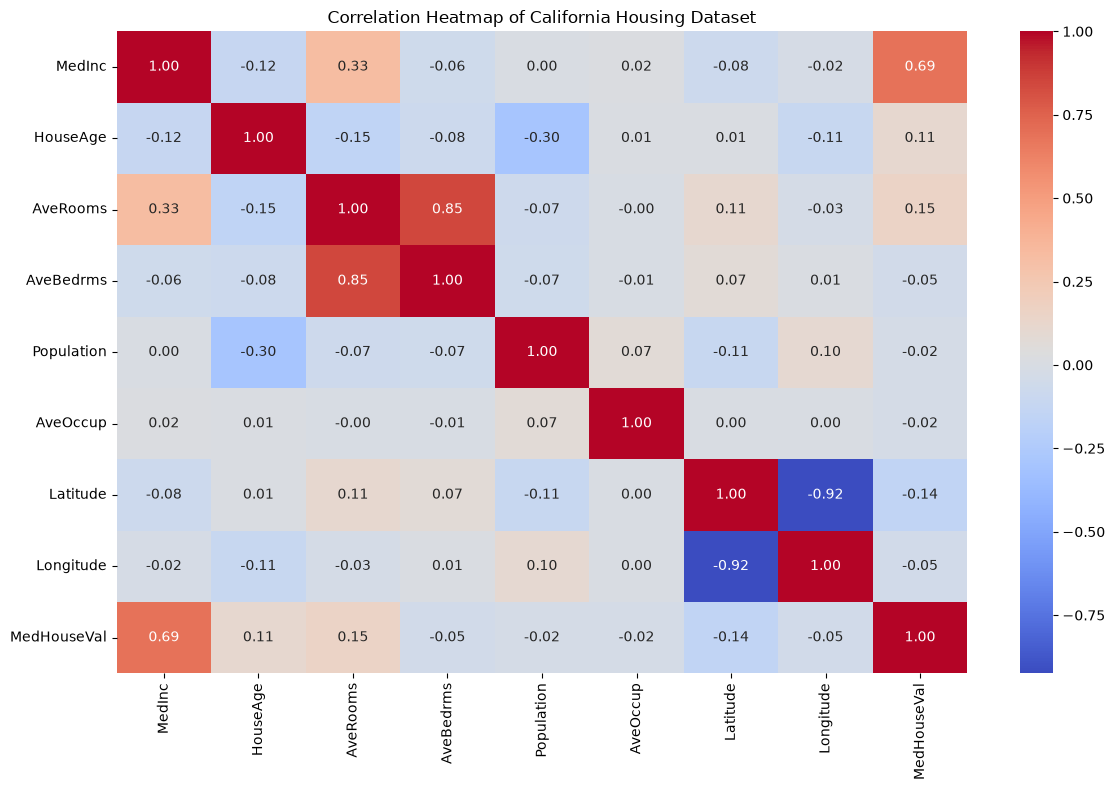

In [5]:
# Calculate correlation between numerical features
correlation = df.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of California Housing Dataset")
plt.tight_layout()
plt.show()

In [6]:
# Separate input features and target variable
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (20640, 8)
Target shape: (20640,)

Feature columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)


In [8]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict house values
linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")
print("First 10 predictions:")
print(linear_predictions[:10])

Linear Regression model trained successfully!
First 10 predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [9]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, linear_predictions)

mse = mean_squared_error(y_test, linear_predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, linear_predictions)

# Display results
print("Linear Regression Evaluation")
print("-----------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Evaluation
-----------------------------
MAE: 0.5332001304956576
MSE: 0.5558915986952445
RMSE: 0.7455813830127765
R2 Score: 0.5757877060324507


In [10]:
# Import Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

# Create the model
tree_model = DecisionTreeRegressor(random_state=42)

# Train the model
tree_model.fit(X_train, y_train)

# Make predictions
tree_predictions = tree_model.predict(X_test)

print("Decision Tree model trained successfully!")
print("First 10 predictions:")
print(tree_predictions[:10])

Decision Tree model trained successfully!
First 10 predictions:
[0.425   1.203   5.00001 2.867   2.257   1.664   2.217   1.707   2.75
 5.00001]


In [11]:
# Calculate evaluation metrics
tree_mae = mean_absolute_error(y_test, tree_predictions)

tree_mse = mean_squared_error(y_test, tree_predictions)

tree_rmse = np.sqrt(tree_mse)

tree_r2 = r2_score(y_test, tree_predictions)

# Display results
print("Decision Tree Evaluation")
print("------------------------")
print("MAE:", tree_mae)
print("MSE:", tree_mse)
print("RMSE:", tree_rmse)
print("R2 Score:", tree_r2)

Decision Tree Evaluation
------------------------
MAE: 0.4567511312984497
MSE: 0.5031085005127663
RMSE: 0.709301417249935
R2 Score: 0.6160675721345087


In [12]:
# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("First 10 predictions:")
print(rf_predictions[:10])

Random Forest model trained successfully!
First 10 predictions:
[0.506     0.73377   4.9353471 2.51476   2.26607   1.66134   2.35358
 1.66422   2.7610306 4.9264689]


In [13]:
# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_mse = mean_squared_error(y_test, rf_predictions)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_predictions)

# Display results
print("Random Forest Evaluation")
print("------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Evaluation
------------------------
MAE: 0.32784343771802343
MSE: 0.25630061992521047
RMSE: 0.5062614146122638
R2 Score: 0.8044117339082415


In [14]:
# Create a comparison table
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [mae, tree_mae, rf_mae],
    "MSE": [mse, tree_mse, rf_mse],
    "RMSE": [rmse, tree_rmse, rf_rmse],
    "R2 Score": [r2, tree_r2, rf_r2]
})

# Display comparison
print("Model Performance Comparison")
display(results.round(4))

Model Performance Comparison


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.5332,0.5559,0.7456,0.5758
1,Decision Tree,0.4568,0.5031,0.7093,0.6161
2,Random Forest,0.3278,0.2563,0.5063,0.8044


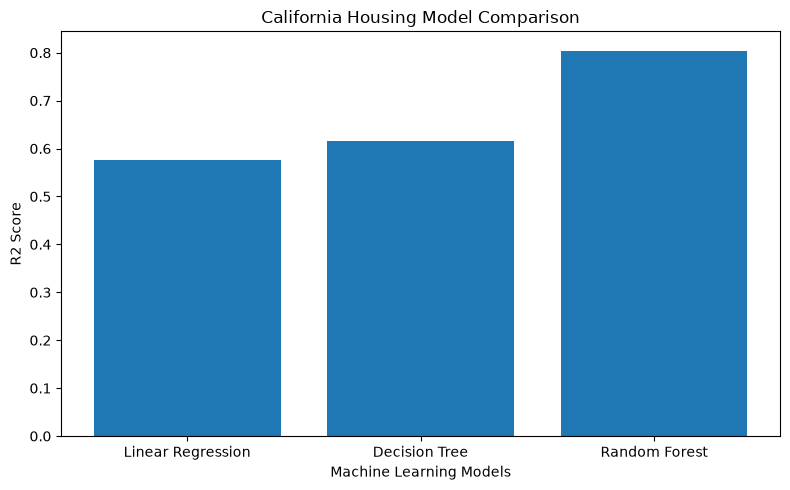

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["R2 Score"])

plt.title("California Housing Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.tight_layout()
plt.show()

In [16]:
# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the results
display(feature_importance)

,Feature,Importance
0,MedInc,0.524955
5,AveOccup,0.138383
6,Latitude,0.088879
7,Longitude,0.088627
1,HouseAge,0.054664
2,AveRooms,0.044202
4,Population,0.030626
3,AveBedrms,0.029665


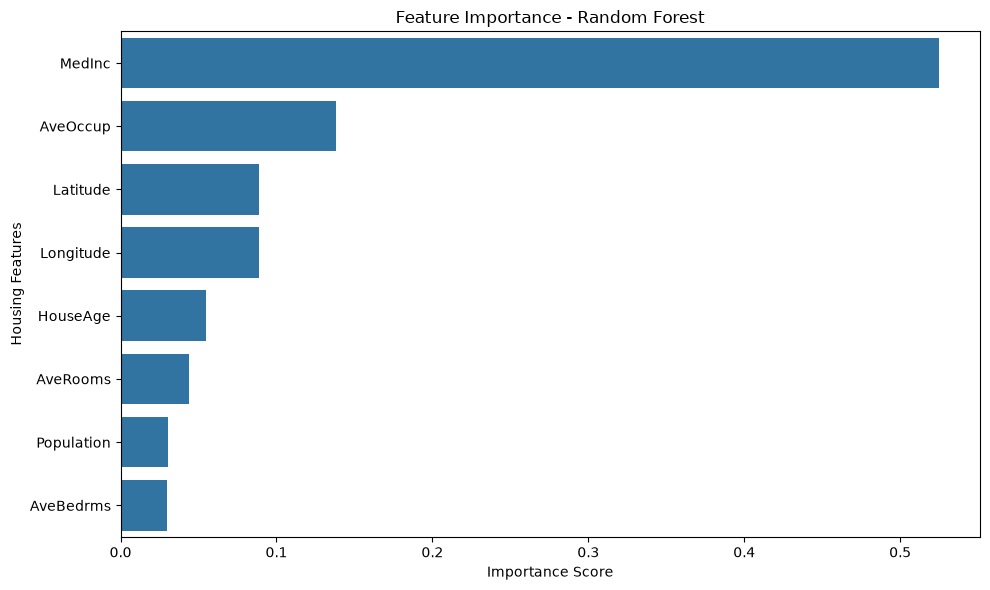

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Housing Features")

plt.tight_layout()
plt.show()

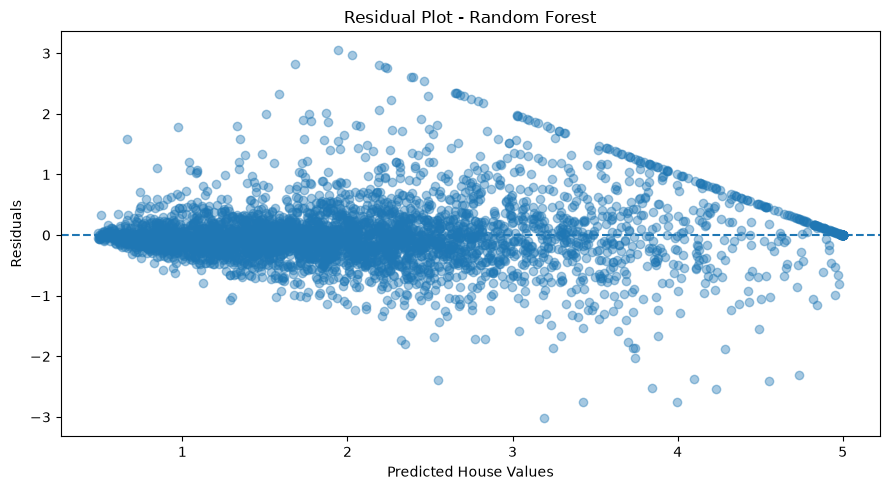

In [18]:
# Calculate residuals for Random Forest
residuals = y_test - rf_predictions

# Plot residuals
plt.figure(figsize=(9, 5))

plt.scatter(
    rf_predictions,
    residuals,
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot - Random Forest")
plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")

plt.tight_layout()
plt.show()

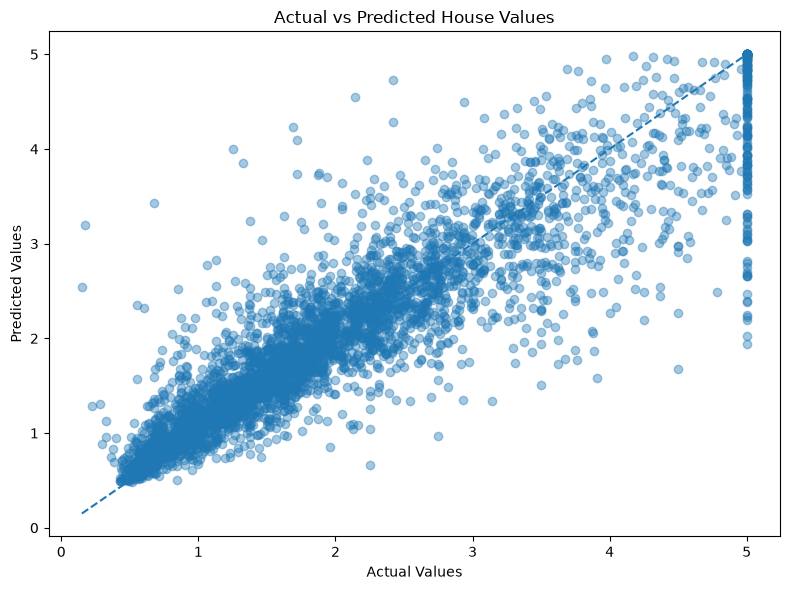

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.tight_layout()
plt.show()

In [20]:
# Save model comparison results
results.to_csv("housing_model_comparison.csv", index=False)

# Save feature importance results
feature_importance.to_csv(
    "housing_feature_importance.csv",
    index=False
)

# Save model comparison chart
plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["R2 Score"])
plt.title("California Housing Model Comparison")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.tight_layout()
plt.savefig("housing_model_comparison.png", dpi=300)
plt.close()

# Save feature importance chart
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)
plt.title("Feature Importance - Random Forest")
plt.tight_layout()
plt.savefig("housing_feature_importance.png", dpi=300)
plt.close()

print("All results and charts saved successfully!")

All results and charts saved successfully!


In [21]:
import joblib

joblib.dump(rf_model, "california_housing_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [22]:
import joblib

joblib.dump(
    rf_model,
    "california_housing_model.pkl",
    compress=3
)

print("Compressed California model saved successfully!")

Compressed California model saved successfully!


In [23]:
import joblib

joblib.dump(
    rf_model,
    "california_housing_model.pkl",
    compress=9
)

print("Maximum compression completed!")

Maximum compression completed!


In [24]:
from sklearn.ensemble import RandomForestRegressor
import joblib

small_model = RandomForestRegressor(
    n_estimators=30,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

small_model.fit(X_train, y_train)

joblib.dump(
    small_model,
    "california_housing_model.pkl",
    compress=3
)

print("Smaller California model saved!")

Smaller California model saved!


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

small_predictions = small_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, small_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, small_predictions)))
print("R2 Score:", r2_score(y_test, small_predictions))

MAE: 0.34950141759349057
RMSE: 0.5253582492744302
R2 Score: 0.7893777479675086
